In [1]:

"""
实现流程:
1.数据采集
2.数据基本处理 画图确定使用哪些参数进行拟合操作
3.数据集预处理
4.模型训练
5.模型评估
6.模型预测
"""
# 导包
from sklearn.datasets import load_iris
from sklearn.preprocessing import  StandardScaler     # 数据标准化
from sklearn.neighbors import KNeighborsClassifier     # KNN近邻分类
from sklearn.model_selection import train_test_split    # 数据集划分
from sklearn.metrics import precision_score
from sklearn.metrics import recall_score
from sklearn.metrics import f1_score
from sklearn.metrics import accuracy_score
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd


In [2]:
# 准备数据
# 导入数据集
iris = load_iris()
print(type(iris))   # 类型类似json
print(iris.keys())  # 查看数据集的键
print(iris.data[0:5])  # 查看数据集的前五个样本
print(iris.target[0:5])  # 查看目标的前五个样本

<class 'sklearn.utils._bunch.Bunch'>
dict_keys(['data', 'target', 'frame', 'target_names', 'DESCR', 'feature_names', 'filename', 'data_module'])
[[5.1 3.5 1.4 0.2]
 [4.9 3.  1.4 0.2]
 [4.7 3.2 1.3 0.2]
 [4.6 3.1 1.5 0.2]
 [5.  3.6 1.4 0.2]]
[0 0 0 0 0]


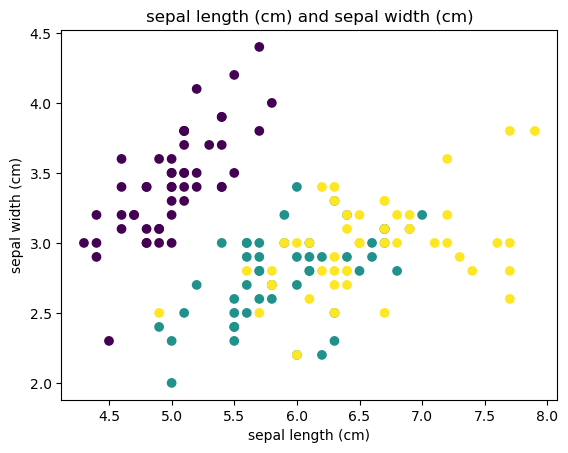

In [23]:
# 画图分析数据
# 创建dataframe对象用于存储数据
iris_df = pd.DataFrame(iris['data'], columns=iris.feature_names)
# 加入标签列
iris_df['target'] = iris.target


# 画图分析数据
# sepal length (cm) 和 sepal width (cm) 两列数据的散点图 最后加上颜色列
plt.scatter(iris_df['sepal length (cm)'], iris_df['sepal width (cm)'], c=iris_df['target'])
plt.xlabel('sepal length (cm)')
plt.ylabel('sepal width (cm)')
plt.title('sepal length (cm) and sepal width (cm)')
plt.show()
# 观察出各个样本排布太集中了 不太适合做样本集

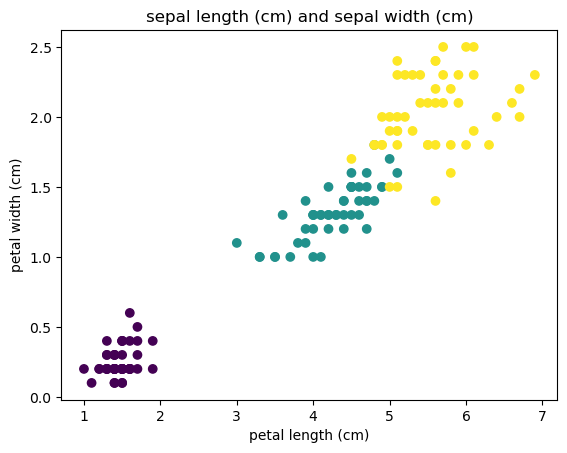

In [ ]:
# 换用另一个作为参数 发现图片便于拟合 花瓣参数
plt.scatter(iris_df['petal length (cm)'], iris_df['petal width (cm)'], c=iris_df['target'])
plt.xlabel('petal length (cm)')
plt.ylabel('petal width (cm)')
plt.title('sepal length (cm) and sepal width (cm)')
plt.show()

In [ ]:
# 构建KNN模型来区分鸢尾花 更改k值和随机种子 观察准确率的变化 
# 1.数据准备
# 切分数据集
# 参数1 数据集 参数2 目标集 参数3 测试数据比列 参数4 随机种子
# 42随机数是一个魔法数字，很多人都用它作为随机种子
x_train,x_test,y_train,y_test = train_test_split(iris.data,iris.target,test_size=0.2,random_state=42)
# 2.数据预处理
# 3.特征工程（数据的标准化）
# 创建一个标准化对象
transform =  StandardScaler()
# 对训练集的特征进行标准化
x_train = transform.fit_transform(x_train)
# 对测试数据的特征进行标准化
x_test = transform.transform(x_test)
# 4.模型训练
# 创建模型对象
model = KNeighborsClassifier(n_neighbors=3)
# 训练模型
model.fit(x_train, y_train)
# 5.模型评估
# 计算准确率
# 参数1 测试数据集 参数2 测试数据集的目标值/标签
score = model.score(x_test, y_test)
print(f"模型准确率: {score:.2f}")
# 6.模型预测
# 创建新数据
x_new = [[4.7, 3.2, 1.3, 0.2],[5.1, 3.5, 1.4, 0.2]]
# 对新数据进行标准化
x_new = transform.transform(x_new)
# 进行预测
# KNN分类结果进行评估
y_pred = model.predict(x_new)
print(f"预测结果: {y_pred}")
y_pred1 = model.predict(x_test)
precision = precision_score(y_test, y_pred1, average='macro')
print(f"模型精准率: {precision:.2f}")
recall = recall_score(y_test, y_pred1, average='macro')
print(f"模型召回率: {recall:.2f}")
f1 = f1_score(y_test, y_pred1, average='macro')
print(f"模型F1-score: {f1:.2f}")

模型准确率: 1.00
预测结果: [0 0]
模型精准率: 1.00
模型召回率: 1.00
模型F1-score: 1.00
